# code_168 · Exact maintenance values before sampled approximations

**Book:** section 32.2. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_32_GUIDE.md), [execution evidence](../CHAPTER_32_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_168).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Rewards, transitions, observation boundaries and independent assessment are defined below. Simulated rewards do not establish field safety or causal identification from arbitrary logs.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=5368;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 5368


<a id="exact-and-sampled-values"></a>
 ## Solve a declared three-state process first
 States 0/1/2 are healthy, worn and failed. Waiting earns 1/0.2/−4 and allows deterioration. Repair costs 1.2 and sends the next state mostly to healthy. The reward is a constructed net operating benefit, not a physical failure-risk estimate. Discount 0.9 gives an infinite-horizon continuing objective. Value iteration supplies the reference; 60,000 actual sampled Q-learning transitions use epsilon 0.3 and visit-dependent step sizes. A separate neural fitted-Q procedure receives 6,000 uniformly sampled state/action transitions, a declared generative sampling service rather than a single trajectory. It uses replay minibatches and a target network. All procedures are fixed, with no final-score checkpoint selection.


,state,exact_wait,exact_repair,tabular_action,neural_action
0,Healthy,6.366972,4.348624,0,0
1,Worn,4.113761,4.348624,1,1
2,Failed,-0.086239,4.348624,1,1


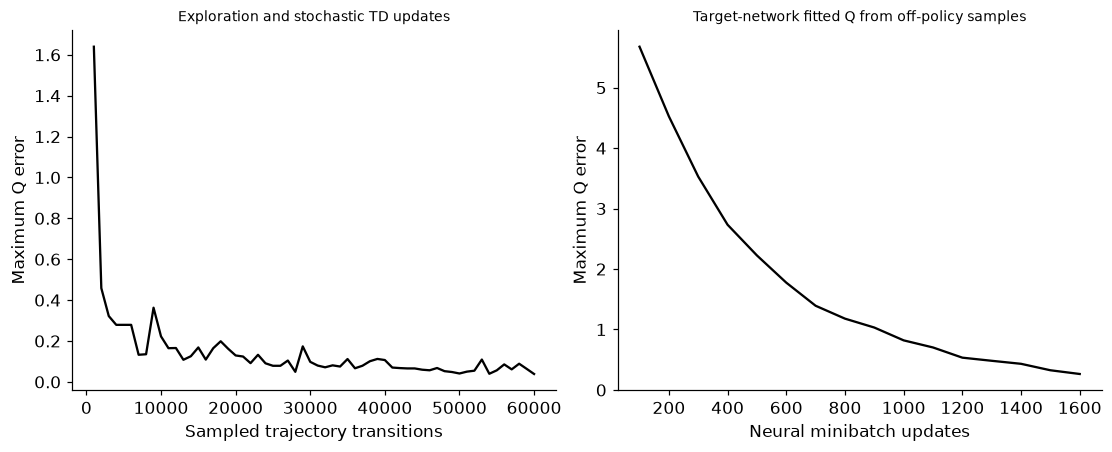

In [2]:
P=np.array([[[.8,.2,0],[.9,.1,0]],[[0,.7,.3],[.9,.1,0]],[[0,0,1],[.9,.1,0]]]);R=np.array([[1.,-1.2],[.2,-1.2],[-4.,-1.2]]);gamma=.9
V=np.zeros(3)
for iteration in range(1000):
    Qstar=R+gamma*np.einsum('sak,k->sa',P,V);new=Qstar.max(1)
    if np.max(abs(new-V))<1e-12:V=new;break
    V=new
Qstar=R+gamma*np.einsum('sak,k->sa',P,V);optimal=Qstar.argmax(1);Q=np.zeros((3,2));visits=np.zeros((3,2),int);s=0;errors=[]
for step in range(60000):
    a=int(rng.integers(2)) if rng.random()<.3 else int(Q[s].argmax());ns=int(rng.choice(3,p=P[s,a]));visits[s,a]+=1;alpha=visits[s,a]**(-.6);Q[s,a]+=alpha*(R[s,a]+gamma*Q[ns].max()-Q[s,a]);s=ns
    if (step+1)%1000==0:errors.append((step+1,float(np.max(abs(Q-Qstar)))))
states=rng.integers(0,3,6000);actions=rng.integers(0,2,6000);next_states=np.array([rng.choice(3,p=P[s,a]) for s,a in zip(states,actions)]);rewards=R[states,actions];eye=torch.eye(3);model=nn.Sequential(nn.Linear(3,16),nn.Tanh(),nn.Linear(16,2));target=copy.deepcopy(model);optimizer=torch.optim.Adam(model.parameters(),lr=.005);neural_trace=[]
for step in range(1600):
    ids=rng.integers(0,6000,64)
    with torch.no_grad():y=torch.tensor(rewards[ids])+gamma*target(eye[next_states[ids]]).max(1).values
    prediction=model(eye[states[ids]])[torch.arange(64),torch.tensor(actions[ids])];loss=nn.functional.mse_loss(prediction,y);optimizer.zero_grad();loss.backward();optimizer.step()
    if (step+1)%50==0:target.load_state_dict(model.state_dict())
    if (step+1)%100==0:
        with torch.no_grad():neural_trace.append((step+1,float(np.max(abs(model(eye).numpy()-Qstar)))))
with torch.no_grad():NQ=model(eye).numpy()
def residual(q):return float(np.max(abs(q-(R+gamma*np.einsum('sak,k->sa',P,q.max(1))))))
assert visits.min()>0 and np.allclose(P.sum(2),1) and residual(Qstar)<1e-10 and np.isfinite(NQ).all()
RESULTS.update(discount=gamma,value_iteration_iterations=iteration+1,exact_Q=Qstar.tolist(),optimal_policy=optimal.tolist(),tabular_Q=Q.tolist(),tabular_policy=Q.argmax(1).tolist(),tabular_visits=visits.tolist(),trajectory_transitions=60000,neural_source_transitions=6000,neural_updates=1600,neural_batch=64,target_copy_interval=50,neural_Q=NQ.tolist(),neural_policy=NQ.argmax(1).tolist(),max_value_errors={'tabular':float(abs(Q-Qstar).max()),'neural':float(abs(NQ-Qstar).max())},Bellman_residuals={'exact':residual(Qstar),'tabular':residual(Q),'neural':residual(NQ)})
display(pd.DataFrame({'state':['Healthy','Worn','Failed'],'exact_wait':Qstar[:,0],'exact_repair':Qstar[:,1],'tabular_action':Q.argmax(1),'neural_action':NQ.argmax(1)}))
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(*np.array(errors).T,color='black');axes[0].set(xlabel='Sampled trajectory transitions',ylabel='Maximum Q error',title='Exploration and stochastic TD updates');axes[1].plot(*np.array(neural_trace).T,color='black');axes[1].set(xlabel='Neural minibatch updates',ylabel='Maximum Q error',title='Target-network fitted Q from off-policy samples');plt.show()


<a id="unsupported-bootstrap-instability"></a>
 ## A tiny approximation can amplify an unsupported value
 Consider two continuing states with zero rewards: stateA transitions toB andB loops. True values are zero. Approximate them by V(A)=w and V(B)=2 w, but admit updates only from externally reset A→B records. The semi-gradient TD residual is(0.95×2−1)w; with step 0.1 it grows by 1.09 per update. B is observed as a successor but never receives its own update. This deliberately restricted dataset exposes bootstrapping plus shared features plus missing update support; it is not a claim that the neural fit above must diverge or that every off-policy dataset is unstable. A target network is a stabilizing device, not a general convergence certificate.


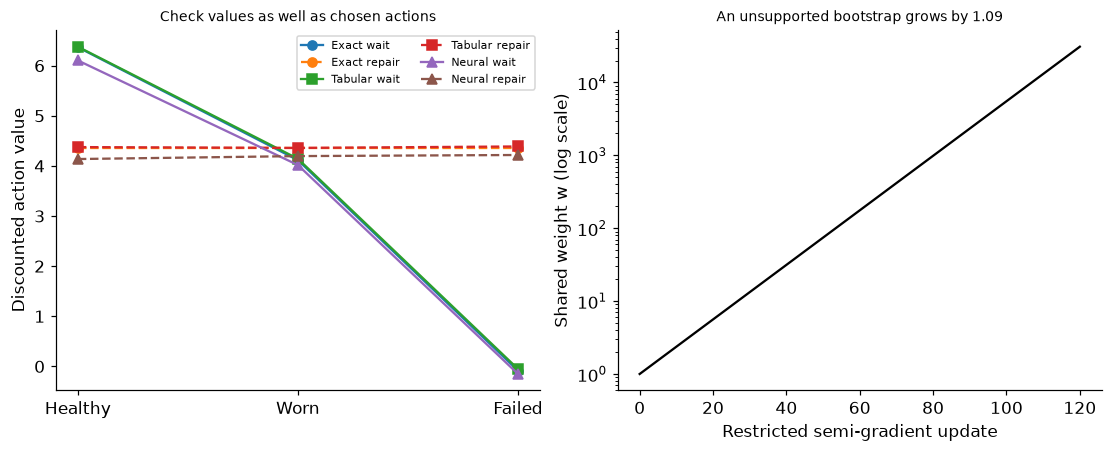

In [3]:
w=1.;history=[w]
for k in range(120):w+=.1*(.95*2*w-w);history.append(w)
np.testing.assert_allclose(w,1.09**120,rtol=1e-12);assert w>1000
RESULTS.update(instability_initial_weight=1.,instability_final_weight=float(w),instability_updates=120,instability_growth_factor=1.09,instability_true_values=[0.,0.],instability_updated_states=['A'],instability_successor_only_states=['B'])
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(3)
for j,(label,q) in enumerate([('Exact',Qstar),('Tabular',Q),('Neural',NQ)]):axes[0].plot(xx,q[:,0],marker=['o','s','^'][j],label=label+' wait');axes[0].plot(xx,q[:,1],linestyle='--',marker=['o','s','^'][j],label=label+' repair')
axes[0].set(xticks=xx,xticklabels=['Healthy','Worn','Failed'],ylabel='Discounted action value',title='Check values as well as chosen actions');axes[0].legend(fontsize=7,ncol=2);axes[1].semilogy(history,color='black');axes[1].set(xlabel='Restricted semi-gradient update',ylabel='Shared weight w (log scale)',title='An unsupported bootstrap grows by 1.09');plt.show()


In [4]:
summary={'example_id':'code_168','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['exact continuing maintenance MDP Bellman solution', 'actual tabular Q-learning from exploratory trajectories', 'actual target-network neural fitted Q iteration from off-policy samples', 'Bellman residual and greedy policy checked against known model', 'explicit unsupported-feature bootstrapping instability'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["exact continuing maintenance MDP Bellman solution", "actual tabular Q-learning from exploratory trajectories", "actual target-network neural fitted Q iteration from off-policy samples", "Bellman residual and greedy policy checked against known model", "explicit unsupported-feature bootstrapping instability"], "elapsed_seconds": 1.234, "example_id": "code_168", "hardware": "Darwin arm64 CPU", "results": {"Bellman_residuals": {"exact": 7.94031507211912e-13, "neural": 0.09586842110199623, "tabular": 0.029490566354645864}, "discount": 0.9, "exact_Q": [[6.366972477056289, 4.348623853203078], [4.113761467881976, 4.348623853203078], [-0.08623853211802368, 4.348623853203078]], "instability_final_weight": 30987.015749194372, "instability_growth_factor": 1.09, "instability_initial_weight": 1.0, "instability_successor_only_states": ["B"], "instability_true_values": [0.0, 0.0], "instability_updated_states": ["A"], "instability_updates": 120, "max_